# Select relevant numerical columns
correlation_columns = [
    'quantity',
    'unit_price',
    'discount_percent',
    'tax_percent',
    'subtotal',
    'total_amount',
    'days_to_pay',
    'payment_delay'
]

correlation_df = df[correlation_columns].copy()

# Calculate correlation
correlation_matrix = correlation_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    'INVOICEIQ – FINANCIAL CORRELATION HEATMAP',
    fontsize=15
)

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("InvoiceIQ Week 2 Started Successfully!")

InvoiceIQ Week 2 Started Successfully!


In [6]:
df = pd.read_csv(
    r"C:\Users\sridevi\Documents\InvoiceIQ\data\processed\invoices_cleaned.csv"
)

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (2000000, 35)


,invoice_id,invoice_number,invoice_date,due_date,customer_id,customer_name,customer_email,customer_city,customer_state,customer_country,...,payment_method,payment_status,payment_date,order_channel,sales_rep,is_overdue,days_to_pay,payment_delay,paid_late,invoice_status
0,2500001,INV-002500001,2025-12-01,2025-12-16,CUST-033946,James Chen,james.chen33946@example.com,Singapore,Singapore,Singapore,...,UPI,Paid,2025-12-05,Online Portal,Rohan Iyer,0,4.0,-11.0,0.0,Paid
1,2500002,INV-002500002,2025-01-04,2025-02-03,CUST-037116,Diya Sharma,diya.sharma37116@example.com,Manchester,England,UK,...,Bank Transfer,Paid,2025-01-25,Marketplace,Karen Kumar,0,21.0,-9.0,0.0,Paid
2,2500003,INV-002500003,2025-07-07,2025-08-06,CUST-027731,Reyansh Nair,reyansh.nair27731@example.com,London,England,UK,...,UPI,Paid,2025-07-21,Phone Order,Richard Miller,0,14.0,-16.0,0.0,Paid
3,2500004,INV-002500004,2025-02-17,2025-03-19,CUST-047646,Arjun Singh,arjun.singh47646@example.com,San Francisco,California,USA,...,Credit Card,Paid,2025-03-11,Walk-in,Krishna Sharma,0,22.0,-8.0,0.0,Paid
4,2500005,INV-002500005,2024-05-09,2024-05-24,CUST-015519,Thomas Wang,thomas.wang15519@example.com,Seattle,Washington,USA,...,Bank Transfer,Overdue,2024-05-24,Sales Rep,Rohan Nair,1,NaN,NaN,NaN,Open


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 35 columns):
 #   Column            Dtype  
---  ------            -----  
 0   invoice_id        int64  
 1   invoice_number    object 
 2   invoice_date      object 
 3   due_date          object 
 4   customer_id       object 
 5   customer_name     object 
 6   customer_email    object 
 7   customer_city     object 
 8   customer_state    object 
 9   customer_country  object 
 10  vendor_id         object 
 11  vendor_name       object 
 12  product_id        object 
 13  product_category  object 
 14  product_name      object 
 15  quantity          int64  
 16  unit_price        float64
 17  discount_percent  float64
 18  tax_percent       float64
 19  subtotal          float64
 20  discount_amount   float64
 21  tax_amount        float64
 22  shipping_cost     float64
 23  total_amount      float64
 24  currency          object 
 25  payment_method    object 
 26  payment_status

In [8]:
df.describe()

,invoice_id,quantity,unit_price,discount_percent,tax_percent,subtotal,discount_amount,tax_amount,shipping_cost,total_amount,is_overdue,days_to_pay,payment_delay,paid_late
count,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,1.358819e+06,1.358819e+06,1358819.0
mean,3.500000e+06,2.549092e+01,1.251969e+03,7.235867e+00,1.465077e+01,3.190568e+04,2.308277e+03,4.336791e+03,4.496471e+01,3.397916e+04,9.988850e-02,1.500379e+01,-1.501869e+01,0.0
std,5.773504e+05,1.442994e+01,7.206427e+02,7.498138e+00,7.024307e+00,2.777701e+04,3.751970e+03,4.706445e+03,4.975435e+01,2.989939e+04,2.998514e-01,1.213643e+01,1.216216e+01,0.0
min,2.500001e+06,1.000000e+00,5.000000e+00,0.000000e+00,0.000000e+00,5.020000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.710000e+00,0.000000e+00,0.000000e+00,-6.000000e+01,0.0
25%,3.000001e+06,1.300000e+01,6.274600e+02,0.000000e+00,1.200000e+01,8.956523e+03,0.000000e+00,8.373300e+02,0.000000e+00,9.485370e+03,0.000000e+00,6.000000e+00,-2.200000e+01,0.0
50%,3.500000e+06,2.500000e+01,1.251320e+03,5.000000e+00,1.800000e+01,2.397252e+04,4.504700e+02,2.694795e+03,2.489000e+01,2.535221e+04,0.000000e+00,1.200000e+01,-1.200000e+01,0.0
75%,4.000000e+06,3.800000e+01,1.877033e+03,1.500000e+01,1.800000e+01,4.861669e+04,3.125220e+03,6.333175e+03,8.750000e+01,5.149472e+04,0.000000e+00,2.200000e+01,-6.000000e+00,0.0
max,4.500000e+06,5.000000e+01,2.500000e+03,2.200000e+01,2.800000e+01,1.249930e+05,2.700860e+04,3.498600e+04,1.500000e+02,1.599360e+05,1.000000e+00,6.000000e+01,0.000000e+00,0.0


In [9]:
# Select important numerical columns

columns = [
    'total_amount',
    'days_to_pay',
    'payment_delay'
]

# Generate summary statistics

summary = df[columns].describe()

display(summary)

,total_amount,days_to_pay,payment_delay
count,2.000000e+06,1.358819e+06,1.358819e+06
mean,3.397916e+04,1.500379e+01,-1.501869e+01
std,2.989939e+04,1.213643e+01,1.216216e+01
min,4.710000e+00,0.000000e+00,-6.000000e+01
25%,9.485370e+03,6.000000e+00,-2.200000e+01
50%,2.535221e+04,1.200000e+01,-1.200000e+01
75%,5.149472e+04,2.200000e+01,-6.000000e+00
max,1.599360e+05,6.000000e+01,0.000000e+00


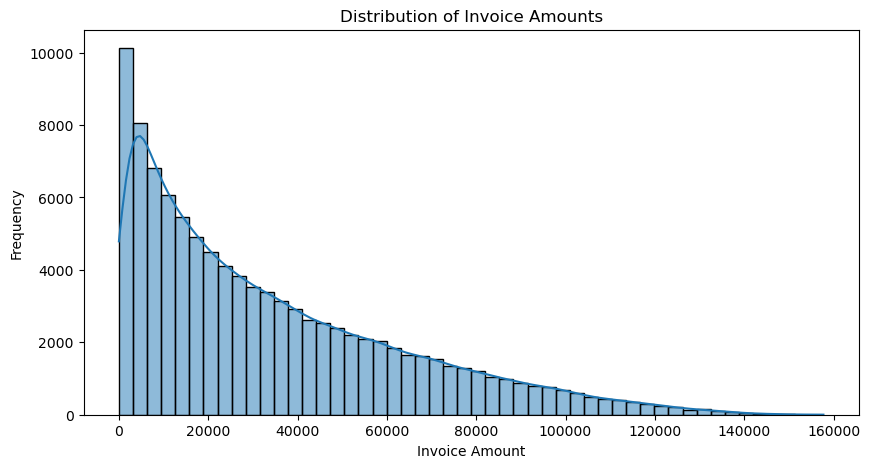

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['total_amount'].dropna().sample(
        n=min(100000, df['total_amount'].notna().sum()),
        random_state=42
    ),
    bins=50,
    kde=True
)

plt.title('Distribution of Invoice Amounts')
plt.xlabel('Invoice Amount')
plt.ylabel('Frequency')

plt.show()

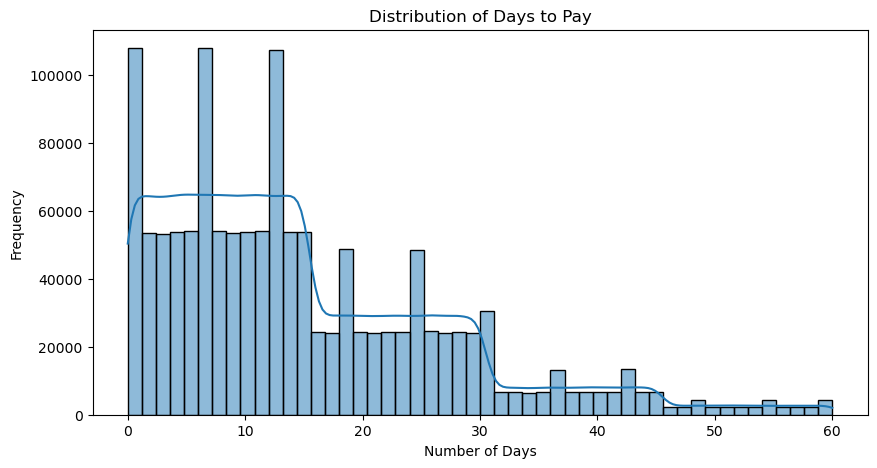

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['days_to_pay'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Days to Pay')
plt.xlabel('Number of Days')
plt.ylabel('Frequency')

plt.show()

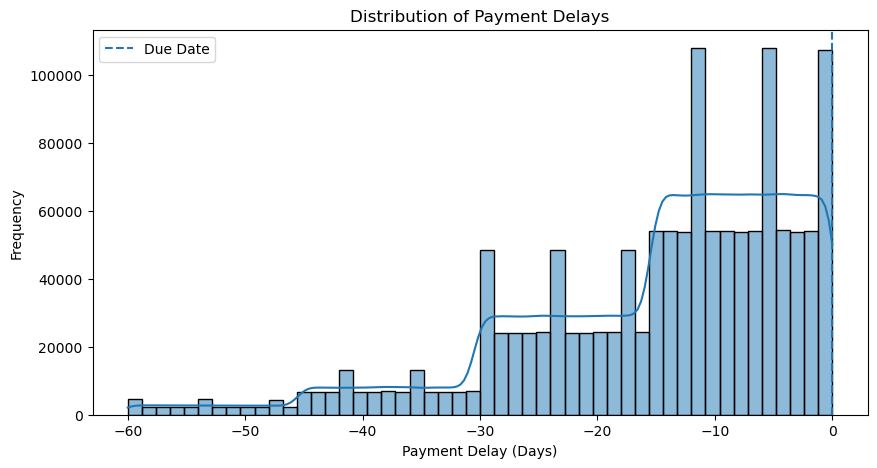

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['payment_delay'].dropna(),
    bins=50,
    kde=True
)

plt.axvline(0, linestyle='--', label='Due Date')

plt.title('Distribution of Payment Delays')
plt.xlabel('Payment Delay (Days)')
plt.ylabel('Frequency')

plt.legend()
plt.show()

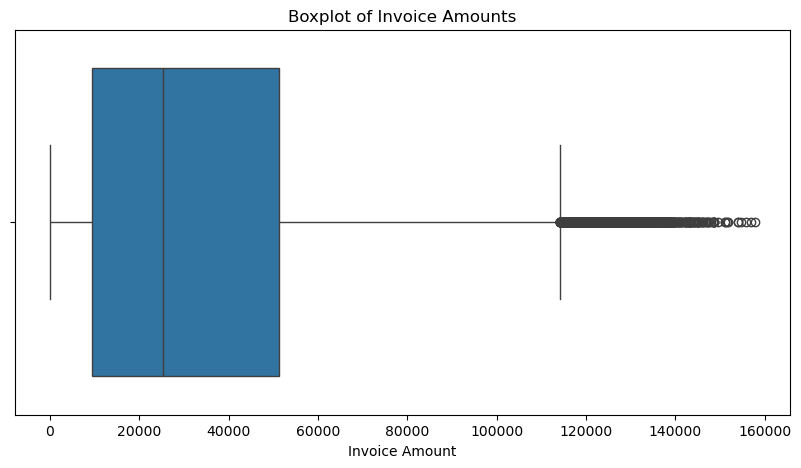

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['total_amount'].sample(
    n=min(100000, len(df)),
    random_state=42
))

plt.title('Boxplot of Invoice Amounts')
plt.xlabel('Invoice Amount')

plt.show()

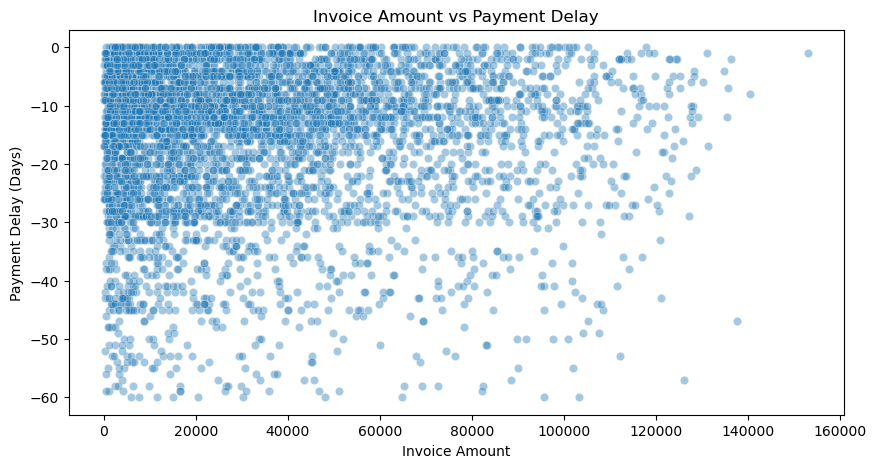

In [15]:
plt.figure(figsize=(10, 5))

sample_df = df[
    ['total_amount', 'payment_delay']
].dropna().sample(5000, random_state=42)

sns.scatterplot(
    data=sample_df,
    x='total_amount',
    y='payment_delay',
    alpha=0.4
)

plt.title('Invoice Amount vs Payment Delay')
plt.xlabel('Invoice Amount')
plt.ylabel('Payment Delay (Days)')
plt.show()

,payment_method,total_invoices,average_delay
4,Debit Card,162612,-14.98
0,Bank Transfer,339783,-15.00
5,Digital Wallet,108682,-15.00
3,Credit Card,340050,-15.02
6,UPI,245019,-15.03
2,Cheque,81496,-15.05
1,Cash,81177,-15.13


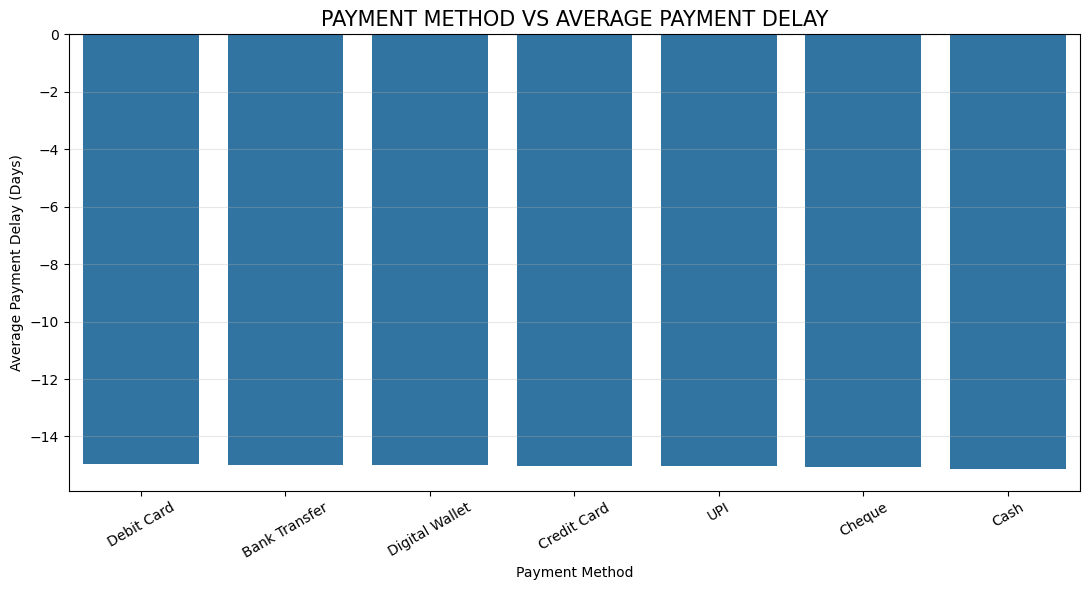

In [68]:
# Analyse payment delay by payment method
method_analysis = (
    df[df['payment_status'] == 'Paid']
    .dropna(subset=['payment_delay'])
    .groupby('payment_method')
    .agg(
        total_invoices=('invoice_id', 'count'),
        average_delay=('payment_delay', 'mean')
    )
    .reset_index()
    .sort_values('average_delay', ascending=False)
)

display(method_analysis.round(2))

# Visualisation
plt.figure(figsize=(11, 6))

sns.barplot(
    data=method_analysis,
    x='payment_method',
    y='average_delay'
)

plt.title(
    'PAYMENT METHOD VS AVERAGE PAYMENT DELAY',
    fontsize=15
)
plt.xlabel('Payment Method')
plt.ylabel('Average Payment Delay (Days)')
plt.xticks(rotation=30)
plt.axhline(y=0, linestyle='--')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

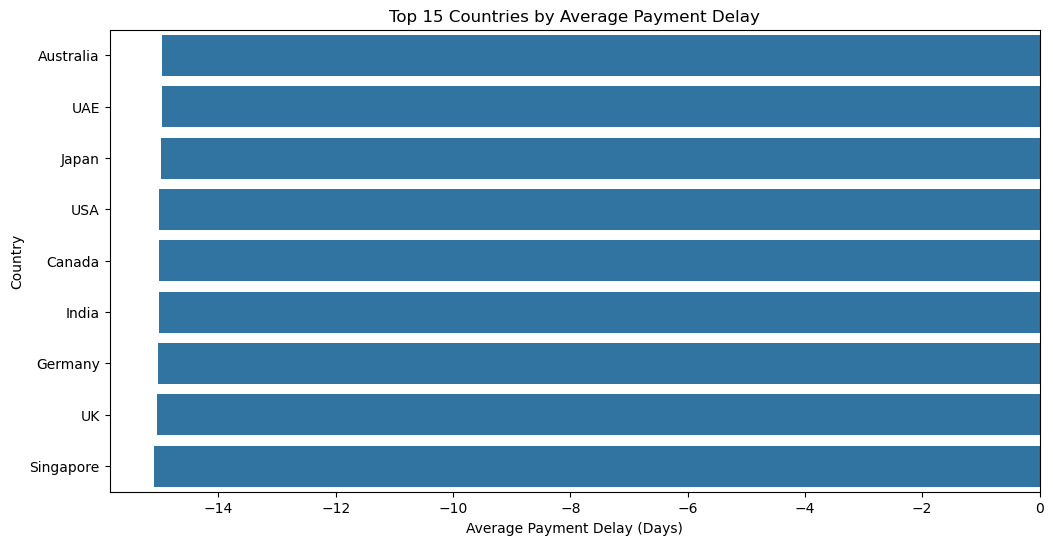

In [17]:
plt.figure(figsize=(12, 6))

country_delay = (
    df[df['payment_status'] == 'Paid']
    .groupby('customer_country')['payment_delay']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

sns.barplot(
    x=country_delay.values,
    y=country_delay.index
)

plt.title('Top 15 Countries by Average Payment Delay')
plt.xlabel('Average Payment Delay (Days)')
plt.ylabel('Country')
plt.show()

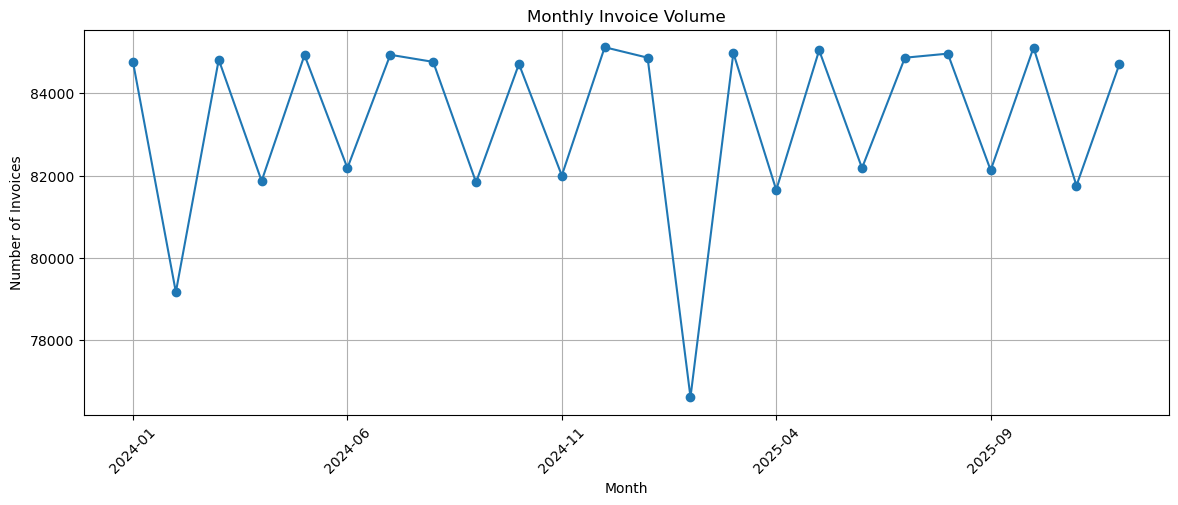

In [18]:
df['invoice_date'] = pd.to_datetime(df['invoice_date'])

df['invoice_month'] = (
    df['invoice_date'].dt.to_period('M').astype(str)
)

monthly_invoices = df.groupby(
    'invoice_month'
).size()

plt.figure(figsize=(14, 5))

monthly_invoices.plot(kind='line', marker='o')

plt.title('Monthly Invoice Volume')
plt.xlabel('Month')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.grid()
plt.show()

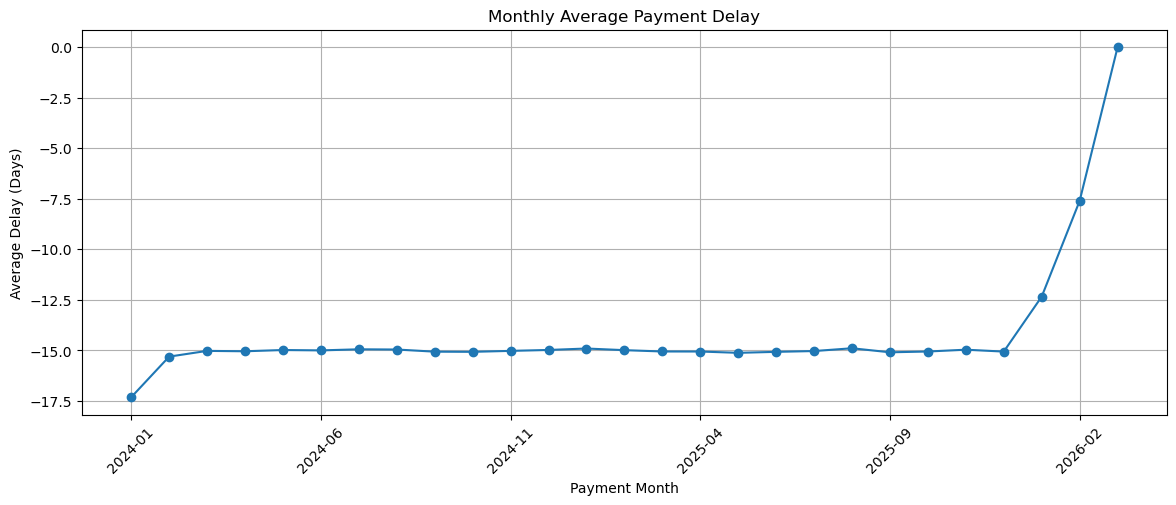

In [19]:
df['payment_month'] = pd.to_datetime(
    df['payment_date']
).dt.to_period('M').astype(str)

monthly_delay = (
    df[df['payment_status'] == 'Paid']
    .groupby('payment_month')['payment_delay']
    .mean()
)

plt.figure(figsize=(14, 5))

monthly_delay.plot(kind='line', marker='o')

plt.title('Monthly Average Payment Delay')
plt.xlabel('Payment Month')
plt.ylabel('Average Delay (Days)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [20]:
# Consider only paid invoices with valid payment delays

paid_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

# Customer-wise payment analysis

customer_analysis = paid_df.groupby(
    ['customer_id', 'customer_name']
).agg(
    total_paid_invoices=('invoice_id', 'count'),
    average_delay=('payment_delay', 'mean'),
    late_payments=('paid_late', 'sum')
).reset_index()

# Calculate late payment percentage

customer_analysis['late_payment_rate'] = (
    customer_analysis['late_payments'] /
    customer_analysis['total_paid_invoices']
) * 100

# Consider customers with at least 5 paid invoices

repeat_customers = customer_analysis[
    customer_analysis['total_paid_invoices'] >= 5
]

# Top 15 customers by average payment delay

top_late_customers = repeat_customers.sort_values(
    by='average_delay',
    ascending=False
).head(15)

display(top_late_customers)

,customer_id,customer_name,total_paid_invoices,average_delay,late_payments,late_payment_rate
29831,CUST-029831,Diya Singh,8,-5.000000,0.0,0.0
12995,CUST-012995,Michael Kim,17,-5.764706,0.0,0.0
39405,CUST-039405,Patricia Davis,13,-5.846154,0.0,0.0
29497,CUST-029497,Park Verma,16,-6.000000,0.0,0.0
30950,CUST-030950,Nisha Li,14,-6.214286,0.0,0.0
311,CUST-000311,Linda Davis,16,-6.500000,0.0,0.0
50652,CUST-050652,Barbara Iyer,12,-6.583333,0.0,0.0
47449,CUST-047449,Park Williams,11,-6.636364,0.0,0.0
39237,CUST-039237,Isha Tanaka,15,-6.666667,0.0,0.0
36855,CUST-036855,Min Smith,11,-6.818182,0.0,0.0


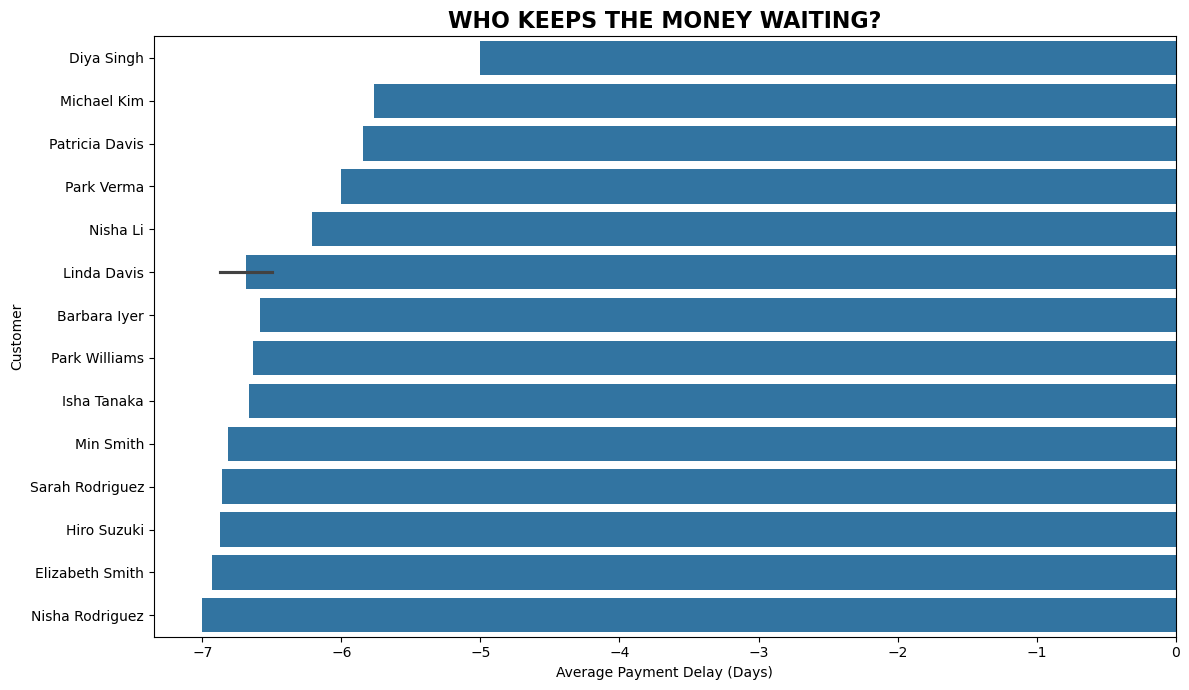

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_late_customers,
    x='average_delay',
    y='customer_name'
)

plt.title(
    'WHO KEEPS THE MONEY WAITING?',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Average Payment Delay (Days)')
plt.ylabel('Customer')

plt.tight_layout()
plt.show()

In [22]:
# Overall customer payment behaviour

payment_behaviour = paid_df['paid_late'].value_counts()

payment_behaviour.index = payment_behaviour.index.map({
    0: 'On-Time / Early Payments',
    1: 'Late Payments'
})

payment_percentage = (
    payment_behaviour / payment_behaviour.sum()
) * 100

display(payment_percentage)

paid_late
On-Time / Early Payments    100.0
Name: count, dtype: float64

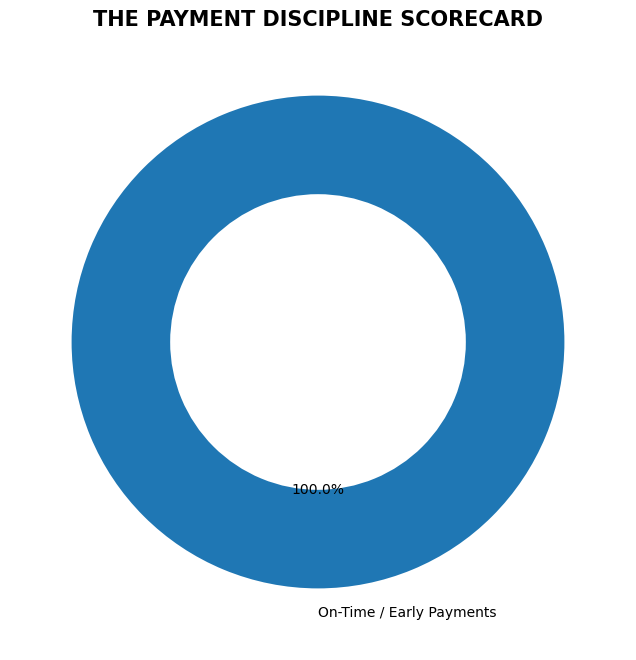

In [23]:
plt.figure(figsize=(8, 8))

plt.pie(
    payment_percentage,
    labels=payment_percentage.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title(
    'THE PAYMENT DISCIPLINE SCORECARD',
    fontsize=15,
    fontweight='bold'
)

plt.show()

In [24]:
# Group customers by invoice frequency

customer_frequency = customer_analysis.copy()

customer_frequency['customer_type'] = np.where(
    customer_frequency['total_paid_invoices'] == 1,
    'One-time Customer',
    np.where(
        customer_frequency['total_paid_invoices'] <= 5,
        'Occasional Customer',
        'Frequent Customer'
    )
)

# Calculate payment behaviour by customer type

frequency_analysis = customer_frequency.groupby(
    'customer_type'
).agg(
    customers=('customer_id', 'nunique'),
    average_delay=('average_delay', 'mean'),
    late_payment_rate=('late_payment_rate', 'mean')
).reset_index()

display(frequency_analysis)

,customer_type,customers,average_delay,late_payment_rate
0,Frequent Customer,59999,-15.016145,0.0
1,Occasional Customer,1,-14.000000,0.0


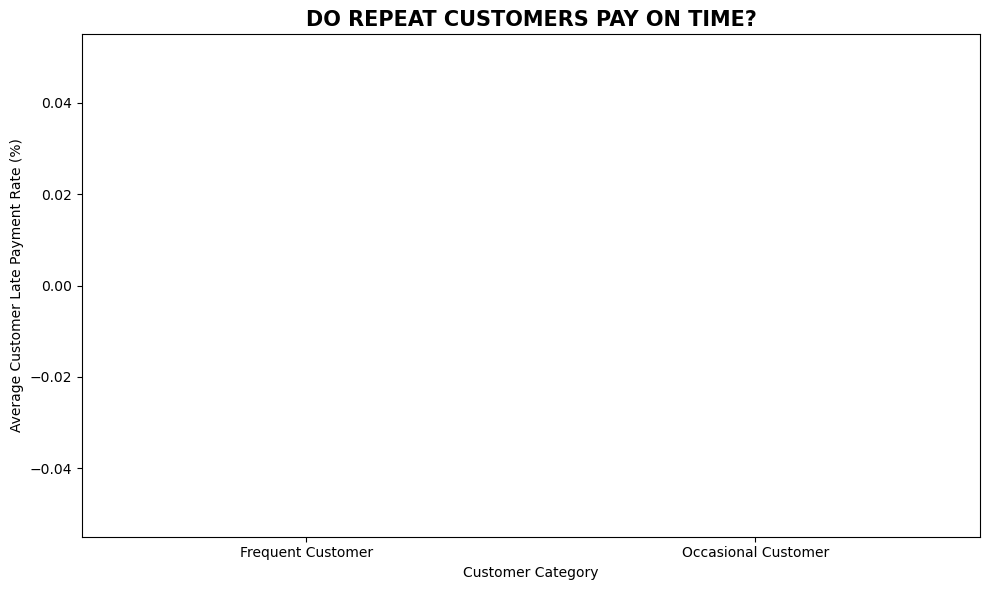

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=frequency_analysis,
    x='customer_type',
    y='late_payment_rate'
)

plt.title(
    'DO REPEAT CUSTOMERS PAY ON TIME?',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Customer Category')
plt.ylabel('Average Customer Late Payment Rate (%)')

plt.tight_layout()
plt.show()

In [26]:
# 1. Total invoices
total_invoices = df['invoice_id'].nunique()

# 2. Total invoice value
total_invoice_value = df['total_amount'].sum()

# 3. Outstanding invoices
# Pending and Overdue statuses only
outstanding_df = df[
    df['payment_status'].isin(['Pending', 'Overdue'])
]

outstanding_count = len(outstanding_df)

outstanding_amount = outstanding_df['total_amount'].sum()

# 4. Overdue invoices
overdue_df = df[
    df['payment_status'] == 'Overdue'
]

overdue_count = len(overdue_df)

overdue_amount = overdue_df['total_amount'].sum()

# 5. Average payment delay among paid invoices
average_delay = df.loc[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna()),
    'payment_delay'
].mean()

# 6. On-time payment percentage
paid_df = df[
    (df['payment_status'] == 'Paid') &
    (df['paid_late'].notna())
]

on_time_percentage = (
    (paid_df['paid_late'] == 0).sum() /
    len(paid_df)
) * 100

print("========== INVOICEIQ FINANCIAL CONTROL ROOM ==========")

print(f"Total Invoices: {total_invoices:,}")

print(f"Total Invoice Value: {total_invoice_value:,.2f}")

print(f"Outstanding Invoices: {outstanding_count:,}")

print(f"Outstanding Amount: {outstanding_amount:,.2f}")

print(f"Overdue Invoices: {overdue_count:,}")

print(f"Overdue Amount: {overdue_amount:,.2f}")

print(f"Average Payment Delay: {average_delay:.2f} days")

print(f"On-Time Payment Rate: {on_time_percentage:.2f}%")

========== INVOICEIQ FINANCIAL CONTROL ROOM ==========
Total Invoices: 2,000,000
Total Invoice Value: 67,958,326,913.58
Outstanding Invoices: 540,792
Outstanding Amount: 18,380,053,504.35
Overdue Invoices: 199,777
Overdue Amount: 6,775,561,121.42
Average Payment Delay: -15.02 days
On-Time Payment Rate: 100.00%


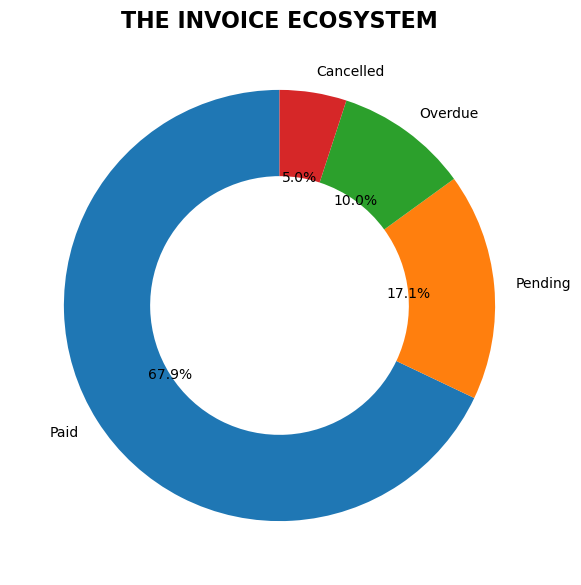

In [27]:
plt.figure(figsize=(9, 7))

status_counts = df['payment_status'].value_counts()

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title(
    'THE INVOICE ECOSYSTEM',
    fontsize=16,
    fontweight='bold'
)

plt.show()

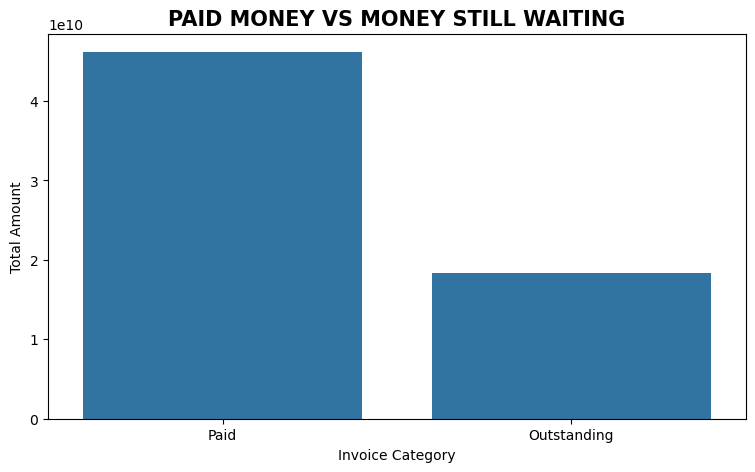

In [28]:
amount_comparison = pd.DataFrame({
    'Category': ['Paid', 'Outstanding'],
    'Amount': [
        df.loc[
            df['payment_status'] == 'Paid',
            'total_amount'
        ].sum(),
        outstanding_amount
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=amount_comparison,
    x='Category',
    y='Amount'
)

plt.title(
    'PAID MONEY VS MONEY STILL WAITING',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Invoice Category')
plt.ylabel('Total Amount')

plt.show()

In [29]:
# Select paid invoices with valid payment delay
bivariate_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

# Select the required columns
bivariate_df = bivariate_df[
    ['total_amount', 'payment_delay']
]

# Remove missing values
bivariate_df = bivariate_df.dropna()

print("Dataset shape:", bivariate_df.shape)
print("\nSummary statistics:")
display(bivariate_df.describe())

Dataset shape: (1358819, 2)

Summary statistics:


,total_amount,payment_delay
count,1.358819e+06,1.358819e+06
mean,3.397404e+04,-1.501869e+01
std,2.988583e+04,1.216216e+01
min,5.140000e+00,-6.000000e+01
25%,9.486595e+03,-2.200000e+01
50%,2.536922e+04,-1.200000e+01
75%,5.147908e+04,-6.000000e+00
max,1.598258e+05,0.000000e+00


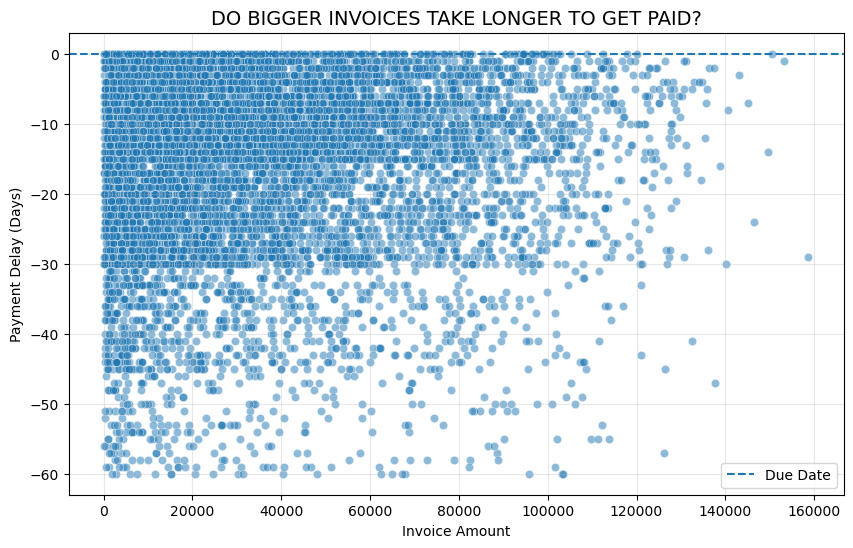

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=bivariate_df.sample(
        min(10000, len(bivariate_df)),
        random_state=42
    ),
    x='total_amount',
    y='payment_delay',
    alpha=0.5
)

plt.axhline(y=0, linestyle='--', label='Due Date')
plt.title(
    'DO BIGGER INVOICES TAKE LONGER TO GET PAID?',
    fontsize=14
)
plt.xlabel('Invoice Amount')
plt.ylabel('Payment Delay (Days)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
correlation = bivariate_df[
    ['total_amount', 'payment_delay']
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

Correlation: -0.001


In [32]:
status_analysis = df.groupby('payment_status').agg(
    invoice_count=('invoice_id', 'count'),
    average_amount=('total_amount', 'mean'),
    median_amount=('total_amount', 'median')
).reset_index()

display(status_analysis.round(2))


,payment_status,invoice_count,average_amount,median_amount
0,Cancelled,100389,34004.75,25381.85
1,Overdue,199777,33915.62,25217.91
2,Paid,1358819,33974.04,25369.22
3,Pending,341015,34029.27,25359.66


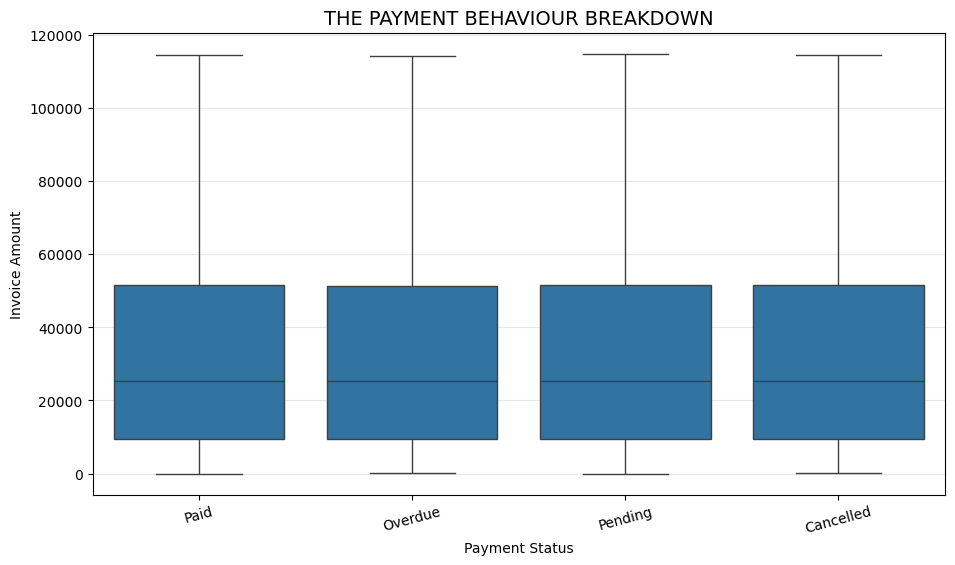

In [33]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='payment_status',
    y='total_amount',
    showfliers=False
)

plt.title(
    'THE PAYMENT BEHAVIOUR BREAKDOWN',
    fontsize=14
)
plt.xlabel('Payment Status')
plt.ylabel('Invoice Amount')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [34]:
country_analysis = (
    df[df['payment_status'] == 'Paid']
    .groupby('customer_country')
    .agg(
        total_invoices=('invoice_id', 'count'),
        average_delay=('payment_delay', 'mean'),
        late_payments=('paid_late', 'sum')
    )
    .reset_index()
)

country_analysis = country_analysis.dropna(
    subset=['average_delay']
)

country_analysis = country_analysis.sort_values(
    by='average_delay',
    ascending=False
)

display(country_analysis.head(15).round(2))

,customer_country,total_invoices,average_delay,late_payments
0,Australia,89464,-14.97,0.0
6,UAE,46125,-14.97,0.0
4,Japan,46061,-14.98,0.0
8,USA,364941,-15.02,0.0
1,Canada,90470,-15.02,0.0
3,India,450984,-15.02,0.0
2,Germany,87916,-15.03,0.0
7,UK,138516,-15.05,0.0
5,Singapore,44342,-15.10,0.0


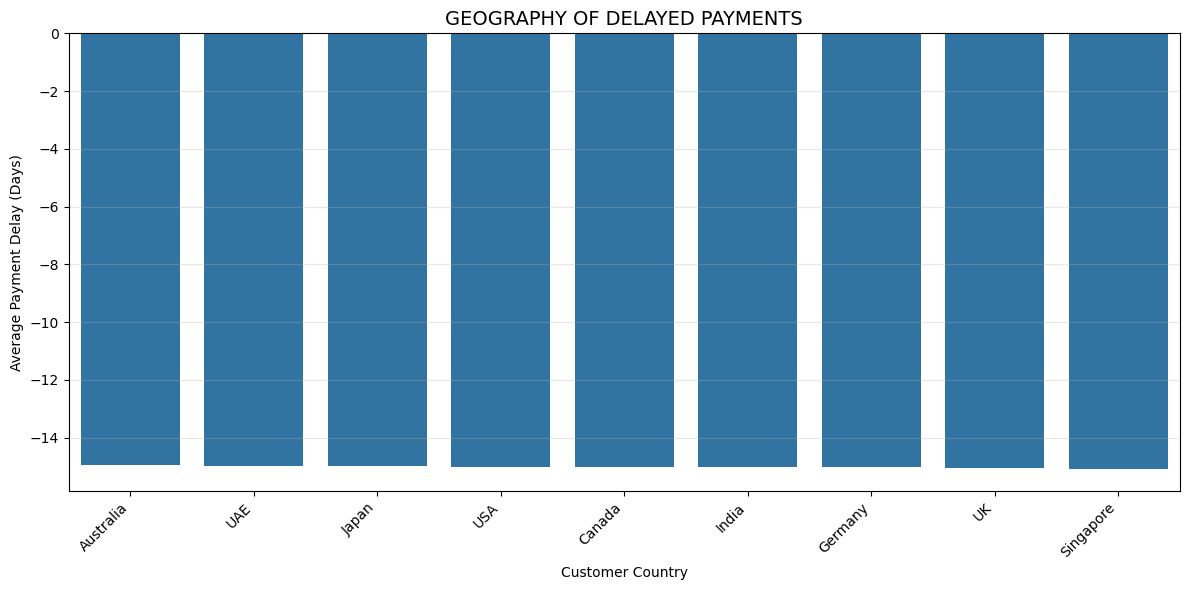

In [35]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_analysis.head(15),
    x='customer_country',
    y='average_delay'
)

plt.title(
    'GEOGRAPHY OF DELAYED PAYMENTS',
    fontsize=14
)
plt.xlabel('Customer Country')
plt.ylabel('Average Payment Delay (Days)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
customer_bivariate = (
    df[df['payment_status'] == 'Paid']
    .groupby(['customer_id', 'customer_name'])
    .agg(
        total_invoices=('invoice_id', 'count'),
        late_payments=('paid_late', 'sum')
    )
    .reset_index()
)

customer_bivariate['late_payment_rate'] = (
    customer_bivariate['late_payments'] /
    customer_bivariate['total_invoices']
) * 100

# Consider customers with at least 5 paid invoices
repeat_customers = customer_bivariate[
    customer_bivariate['total_invoices'] >= 5
]

display(repeat_customers.sort_values(
    'late_payment_rate',
    ascending=False
).head(15).round(2))

,customer_id,customer_name,total_invoices,late_payments,late_payment_rate
0,CUST-000000,Arjun Patel,26,0.0,0.0
1,CUST-000001,Sarah Smith,10,0.0,0.0
2,CUST-000002,Jennifer Wang,22,0.0,0.0
3,CUST-000003,John Williams,26,0.0,0.0
4,CUST-000004,John Singh,22,0.0,0.0
5,CUST-000005,Hiro Watanabe,22,0.0,0.0
6,CUST-000006,Arjun Singh,20,0.0,0.0
7,CUST-000007,Elizabeth Patel,16,0.0,0.0
8,CUST-000008,Ananya Johnson,24,0.0,0.0
9,CUST-000009,Arjun Gupta,15,0.0,0.0


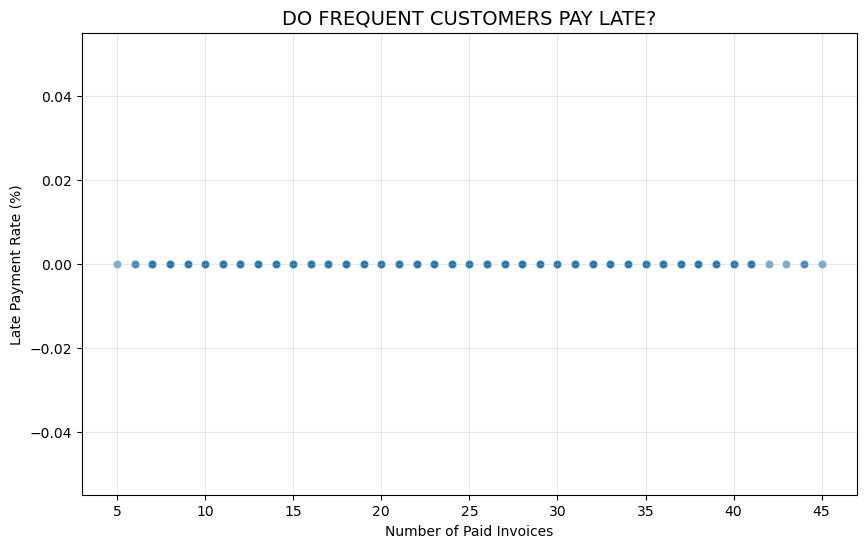

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=repeat_customers,
    x='total_invoices',
    y='late_payment_rate',
    alpha=0.6
)

plt.title(
    'DO FREQUENT CUSTOMERS PAY LATE?',
    fontsize=14
)
plt.xlabel('Number of Paid Invoices')
plt.ylabel('Late Payment Rate (%)')
plt.grid(alpha=0.3)
plt.show()

In [38]:
customer_correlation = repeat_customers[
    ['total_invoices', 'late_payment_rate']
].corr().iloc[0, 1]

print(
    "Customer Invoice Count vs Late Payment Rate:",
    round(customer_correlation, 3)
)

Customer Invoice Count vs Late Payment Rate: nan


In [39]:
# Create a separate analysis dataframe
monthly_delay = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

# Extract month from invoice date
monthly_delay['invoice_month'] = (
    pd.to_datetime(monthly_delay['invoice_date']).dt.month_name()
)

# Calculate average payment delay
month_analysis = monthly_delay.groupby('invoice_month').agg(
    total_invoices=('invoice_id', 'count'),
    average_delay=('payment_delay', 'mean')
).reset_index()

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

month_analysis['invoice_month'] = pd.Categorical(
    month_analysis['invoice_month'],
    categories=month_order,
    ordered=True
)

month_analysis = month_analysis.sort_values('invoice_month')

display(month_analysis.round(2))

,invoice_month,total_invoices,average_delay
4,January,115090,-15.00
3,February,105862,-15.00
7,March,115418,-15.04
0,April,111437,-15.05
8,May,115225,-15.05
6,June,111529,-15.01
5,July,115183,-14.99
1,August,115452,-14.96
11,September,111261,-15.06
10,October,115520,-15.07


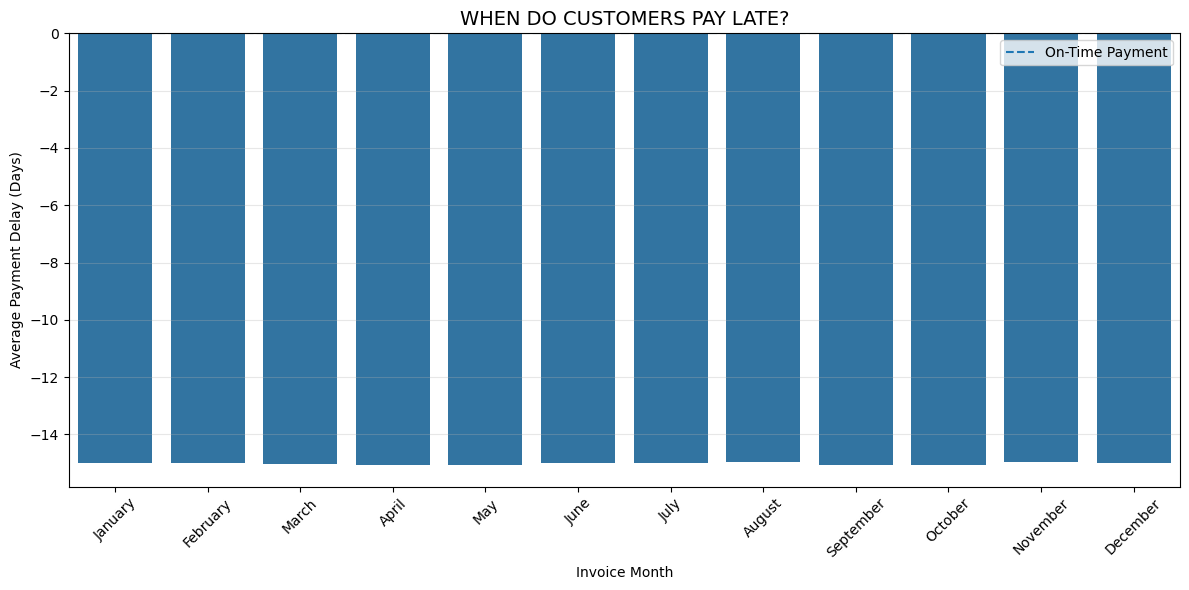

In [40]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=month_analysis,
    x='invoice_month',
    y='average_delay'
)

plt.title(
    'WHEN DO CUSTOMERS PAY LATE?',
    fontsize=14
)
plt.xlabel('Invoice Month')
plt.ylabel('Average Payment Delay (Days)')
plt.xticks(rotation=45)
plt.axhline(y=0, linestyle='--', label='On-Time Payment')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Make a copy of the dataset
time_df = df.copy()

# Convert invoice date to datetime
time_df['invoice_date'] = pd.to_datetime(
    time_df['invoice_date']
)

# Extract year and month
time_df['invoice_month'] = (
    time_df['invoice_date'].dt.to_period('M')
)

# Count invoices per month
monthly_invoices = time_df.groupby(
    'invoice_month'
).agg(
    total_invoices=('invoice_id', 'count'),
    total_invoice_amount=('total_amount', 'sum')
).reset_index()

# Convert period into readable text
monthly_invoices['invoice_month'] = (
    monthly_invoices['invoice_month'].astype(str)
)

display(monthly_invoices)

,invoice_month,total_invoices,total_invoice_amount
0,2024-01,84766,2.870637e+09
1,2024-02,79169,2.696123e+09
2,2024-03,84819,2.870141e+09
3,2024-04,81870,2.789728e+09
4,2024-05,84930,2.887157e+09
5,2024-06,82184,2.799248e+09
6,2024-07,84937,2.895000e+09
7,2024-08,84765,2.872207e+09
8,2024-09,81839,2.783592e+09
9,2024-10,84713,2.868617e+09


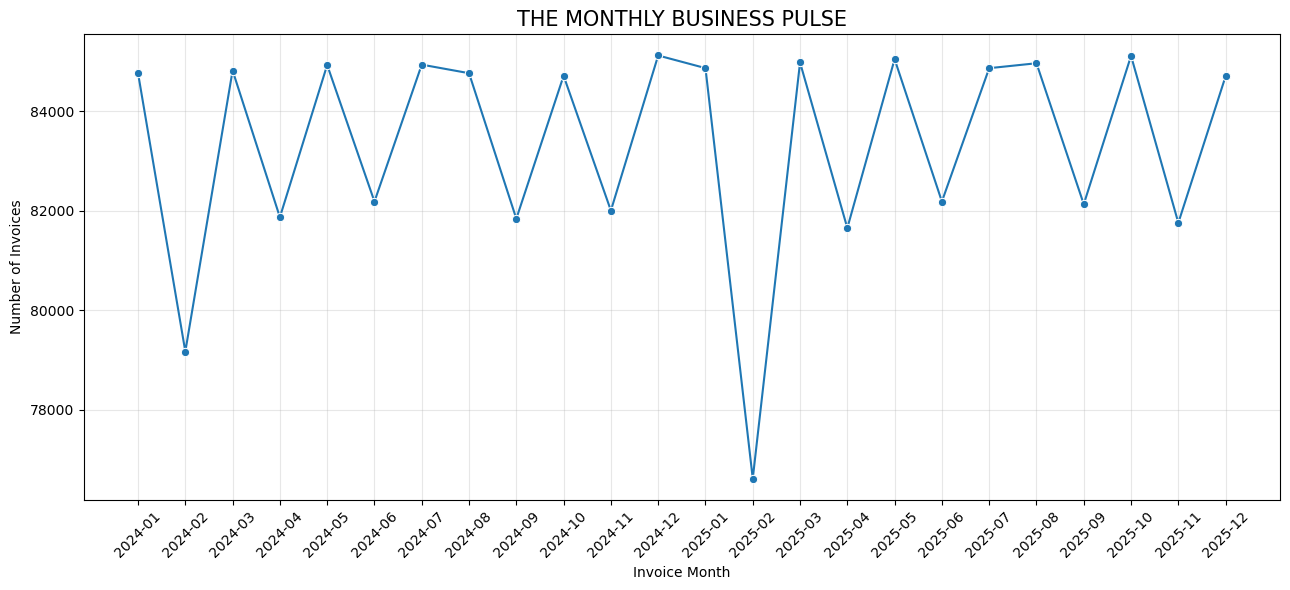

In [42]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_invoices,
    x='invoice_month',
    y='total_invoices',
    marker='o'
)

plt.title(
    'THE MONTHLY BUSINESS PULSE',
    fontsize=15
)
plt.xlabel('Invoice Month')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Select successfully paid invoices
delay_time_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

# Extract invoice month
delay_time_df['invoice_month'] = (
    pd.to_datetime(delay_time_df['invoice_date'])
    .dt.to_period('M')
)

# Calculate monthly payment delay
monthly_delay_trend = delay_time_df.groupby(
    'invoice_month'
).agg(
    total_paid_invoices=('invoice_id', 'count'),
    average_delay=('payment_delay', 'mean')
).reset_index()

monthly_delay_trend['invoice_month'] = (
    monthly_delay_trend['invoice_month'].astype(str)
)

display(monthly_delay_trend.round(2))

,invoice_month,total_paid_invoices,average_delay
0,2024-01,57439,-15.04
1,2024-02,53915,-15.03
2,2024-03,57774,-14.98
3,2024-04,55641,-15.05
4,2024-05,57733,-14.97
5,2024-06,55758,-15.02
6,2024-07,57717,-14.96
7,2024-08,57661,-15.00
8,2024-09,55478,-15.04
9,2024-10,57523,-15.08


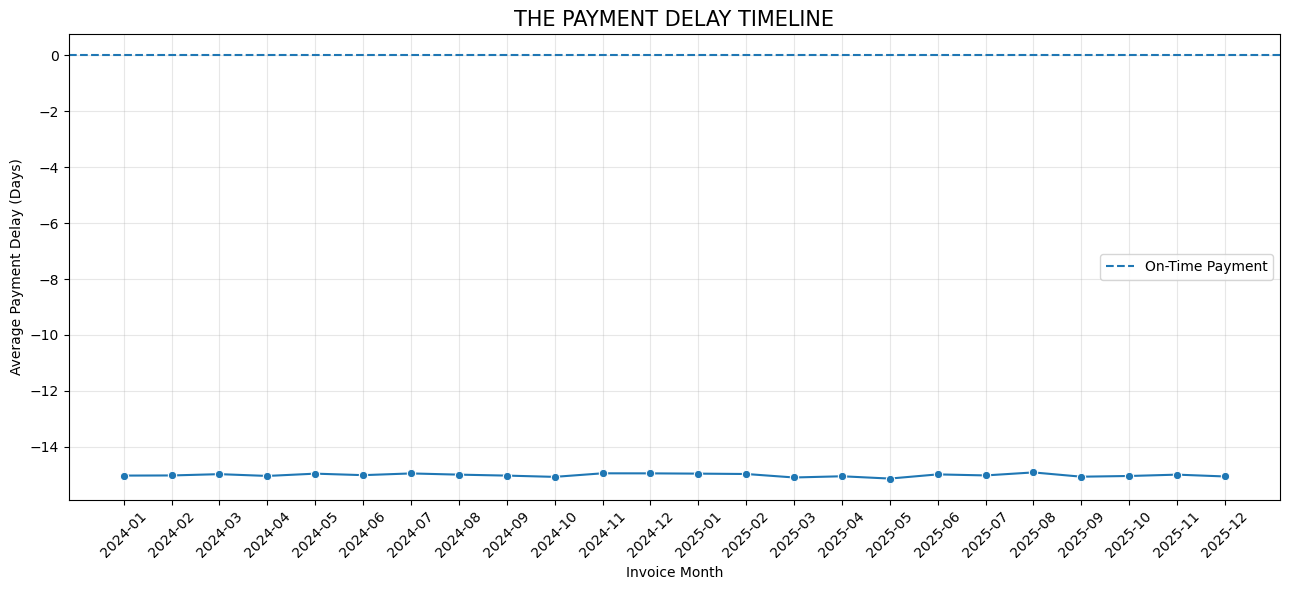

In [44]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_delay_trend,
    x='invoice_month',
    y='average_delay',
    marker='o'
)

plt.axhline(
    y=0,
    linestyle='--',
    label='On-Time Payment'
)

plt.title(
    'THE PAYMENT DELAY TIMELINE',
    fontsize=15
)

plt.xlabel('Invoice Month')
plt.ylabel('Average Payment Delay (Days)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
display(
    monthly_delay_trend[
        ['invoice_month', 'total_paid_invoices', 'average_delay']
    ].round(2)
)

,invoice_month,total_paid_invoices,average_delay
0,2024-01,57439,-15.04
1,2024-02,53915,-15.03
2,2024-03,57774,-14.98
3,2024-04,55641,-15.05
4,2024-05,57733,-14.97
5,2024-06,55758,-15.02
6,2024-07,57717,-14.96
7,2024-08,57661,-15.00
8,2024-09,55478,-15.04
9,2024-10,57523,-15.08


In [46]:
print("Overall average delay:",
      round(delay_time_df['payment_delay'].mean(), 2))

print("\nPayment delay distribution:")
display(delay_time_df['payment_delay'].describe())

Overall average delay: -15.02

Payment delay distribution:


count    1.358819e+06
mean    -1.501869e+01
std      1.216216e+01
min     -6.000000e+01
25%     -2.200000e+01
50%     -1.200000e+01
75%     -6.000000e+00
max      0.000000e+00
Name: payment_delay, dtype: float64

In [47]:
print(
    delay_time_df['paid_late']
    .value_counts(dropna=False)
)

print("\nPayment behaviour percentage:")
display(
    delay_time_df['paid_late']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

paid_late
0.0    1358819
Name: count, dtype: int64

Payment behaviour percentage:


paid_late
0.0    100.0
Name: proportion, dtype: float64

In [48]:
seasonal_df = df.copy()

seasonal_df['invoice_date'] = pd.to_datetime(
    seasonal_df['invoice_date']
)

seasonal_df['month_name'] = (
    seasonal_df['invoice_date'].dt.month_name()
)

seasonal_df['month_number'] = (
    seasonal_df['invoice_date'].dt.month
)

seasonal_analysis = seasonal_df.groupby(
    ['month_number', 'month_name']
).agg(
    total_invoices=('invoice_id', 'count'),
    average_invoice_amount=('total_amount', 'mean')
).reset_index()

seasonal_analysis = seasonal_analysis.sort_values(
    'month_number'
)

display(seasonal_analysis.round(2))

,month_number,month_name,total_invoices,average_invoice_amount
0,1,January,169633,33909.82
1,2,February,155784,34071.04
2,3,March,169800,33909.53
3,4,April,163522,33930.93
4,5,May,169977,33967.37
5,6,June,164369,33923.17
6,7,July,169803,34074.47
7,8,August,169730,33892.82
8,9,September,163970,34067.49
9,10,October,169826,33943.42


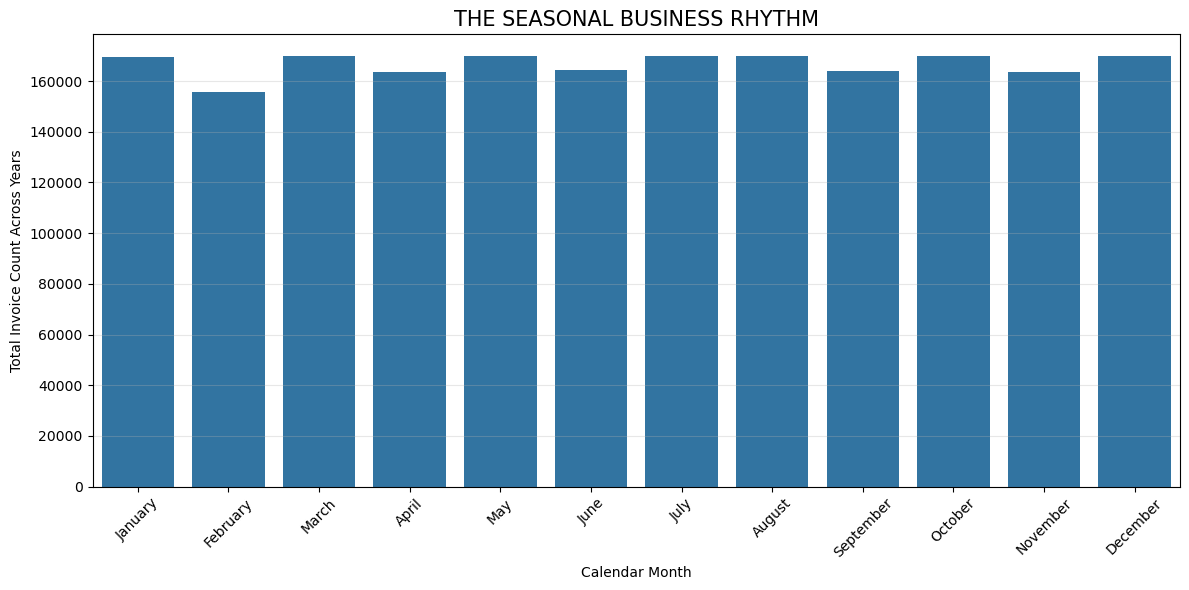

In [49]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_analysis,
    x='month_name',
    y='total_invoices'
)

plt.title(
    'THE SEASONAL BUSINESS RHYTHM',
    fontsize=15
)

plt.xlabel('Calendar Month')
plt.ylabel('Total Invoice Count Across Years')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
month_end_df = df.copy()

month_end_df['invoice_date'] = pd.to_datetime(
    month_end_df['invoice_date']
)

# Extract day and total days in the month
month_end_df['day'] = month_end_df['invoice_date'].dt.day

month_end_df['days_in_month'] = (
    month_end_df['invoice_date'].dt.days_in_month
)

# Categorise invoice dates
month_end_df['invoice_period'] = np.select(
    [
        month_end_df['day'] <= 5,
        month_end_df['day'] >= month_end_df['days_in_month'] - 4
    ],
    [
        'Beginning (First 5 Days)',
        'Month-End (Last 5 Days)'
    ],
    default='Middle of Month'
)

# Count invoices in each period
month_end_analysis = month_end_df.groupby(
    'invoice_period'
).agg(
    total_invoices=('invoice_id', 'count')
).reset_index()

display(month_end_analysis)

,invoice_period,total_invoices
0,Beginning (First 5 Days),328267
1,Middle of Month,1343704
2,Month-End (Last 5 Days),328029


In [51]:
month_end_analysis['percentage'] = (
    month_end_analysis['total_invoices'] /
    month_end_analysis['total_invoices'].sum()
) * 100

display(month_end_analysis.round(2))

,invoice_period,total_invoices,percentage
0,Beginning (First 5 Days),328267,16.41
1,Middle of Month,1343704,67.19
2,Month-End (Last 5 Days),328029,16.40


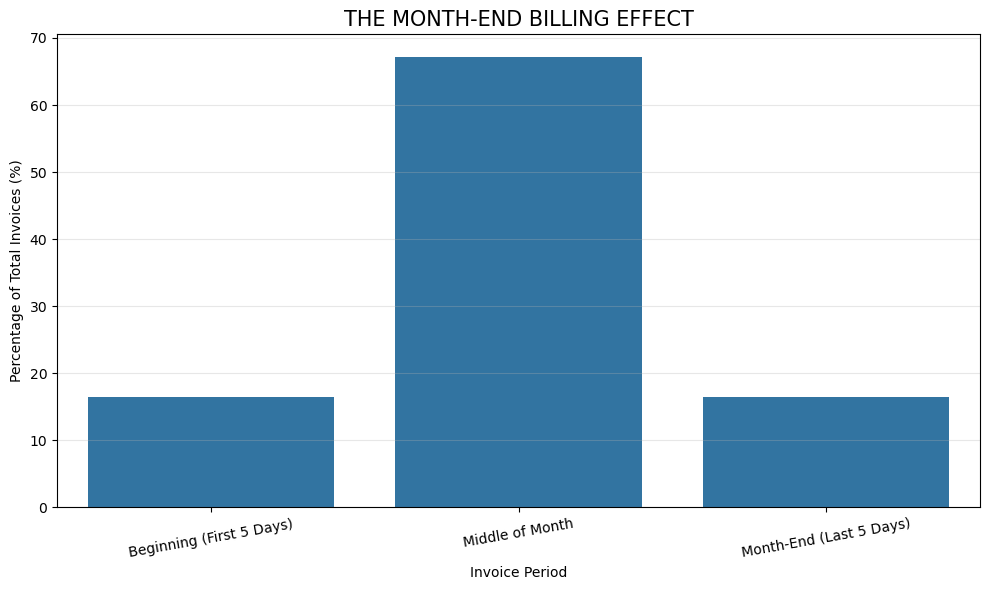

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=month_end_analysis,
    x='invoice_period',
    y='percentage'
)

plt.title(
    'THE MONTH-END BILLING EFFECT',
    fontsize=15
)

plt.xlabel('Invoice Period')
plt.ylabel('Percentage of Total Invoices (%)')
plt.xticks(rotation=10)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
quarter_df = df.copy()

quarter_df['invoice_date'] = pd.to_datetime(
    quarter_df['invoice_date']
)

# Find the last date of each calendar quarter
quarter_df['quarter_end'] = (
    quarter_df['invoice_date']
    .dt.to_period('Q')
    .dt.end_time
    .dt.normalize()
)

# Calculate days remaining until quarter-end
quarter_df['days_to_quarter_end'] = (
    quarter_df['quarter_end'] - quarter_df['invoice_date'].dt.normalize()
).dt.days

# Categorise invoices
quarter_df['quarter_period'] = np.where(
    quarter_df['days_to_quarter_end'] <= 4,
    'Quarter-End (Last 5 Days)',
    'Other Quarter Days'
)

display(
    quarter_df['quarter_period'].value_counts()
)

quarter_period
Other Quarter Days           1890479
Quarter-End (Last 5 Days)     109521
Name: count, dtype: int64

In [54]:
quarter_analysis = quarter_df.groupby(
    'quarter_period'
).agg(
    total_invoices=('invoice_id', 'count')
).reset_index()

quarter_analysis['percentage'] = (
    quarter_analysis['total_invoices'] /
    quarter_analysis['total_invoices'].sum()
) * 100

display(quarter_analysis.round(2))

,quarter_period,total_invoices,percentage
0,Other Quarter Days,1890479,94.52
1,Quarter-End (Last 5 Days),109521,5.48


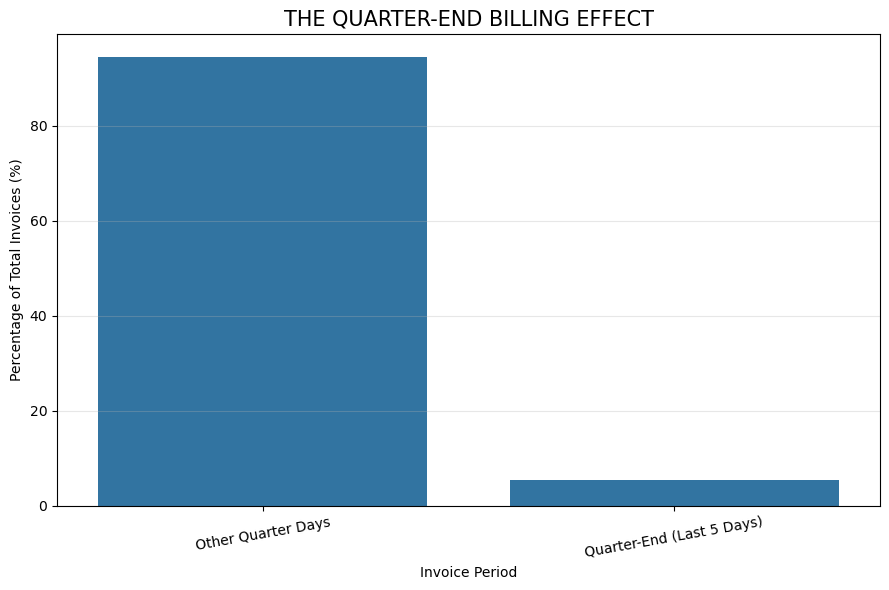

In [55]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=quarter_analysis,
    x='quarter_period',
    y='percentage'
)

plt.title(
    'THE QUARTER-END BILLING EFFECT',
    fontsize=15
)

plt.xlabel('Invoice Period')
plt.ylabel('Percentage of Total Invoices (%)')
plt.xticks(rotation=10)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
numeric_df = df.select_dtypes(include=['number'])

print("Numerical columns:")
print(numeric_df.columns.tolist())

Numerical columns:
['invoice_id', 'quantity', 'unit_price', 'discount_percent', 'tax_percent', 'subtotal', 'discount_amount', 'tax_amount', 'shipping_cost', 'total_amount', 'is_overdue', 'days_to_pay', 'payment_delay', 'paid_late']


In [57]:
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

,invoice_id,quantity,unit_price,discount_percent,tax_percent,subtotal,discount_amount,tax_amount,shipping_cost,total_amount,is_overdue,days_to_pay,payment_delay,paid_late
invoice_id,1.0,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.0,0.00,-0.0,-0.00,0.00,NaN
quantity,-0.0,1.00,-0.00,0.00,-0.00,0.65,0.35,0.52,0.0,0.64,-0.0,0.00,-0.00,NaN
unit_price,-0.0,-0.00,1.00,-0.00,0.00,0.66,0.35,0.53,0.0,0.65,0.0,-0.00,-0.00,NaN
discount_percent,-0.0,0.00,-0.00,1.00,0.00,-0.00,0.64,-0.08,-0.0,-0.09,-0.0,-0.00,0.00,NaN
tax_percent,0.0,-0.00,0.00,0.00,1.00,0.00,-0.00,0.44,0.0,0.07,-0.0,0.00,0.00,NaN
subtotal,-0.0,0.65,0.66,-0.00,0.00,1.00,0.53,0.80,0.0,0.99,-0.0,0.00,-0.00,NaN
discount_amount,-0.0,0.35,0.35,0.64,-0.00,0.53,1.00,0.35,-0.0,0.43,-0.0,0.00,-0.00,NaN
tax_amount,0.0,0.52,0.53,-0.08,0.44,0.80,0.35,1.00,0.0,0.86,-0.0,0.00,-0.00,NaN
shipping_cost,0.0,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,1.0,0.00,-0.0,0.00,0.00,NaN
total_amount,0.0,0.64,0.65,-0.09,0.07,0.99,0.43,0.86,0.0,1.00,-0.0,0.00,-0.00,NaN


correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("Top 10 strongest numerical relationships:")
display(correlation_pairs.head(10))

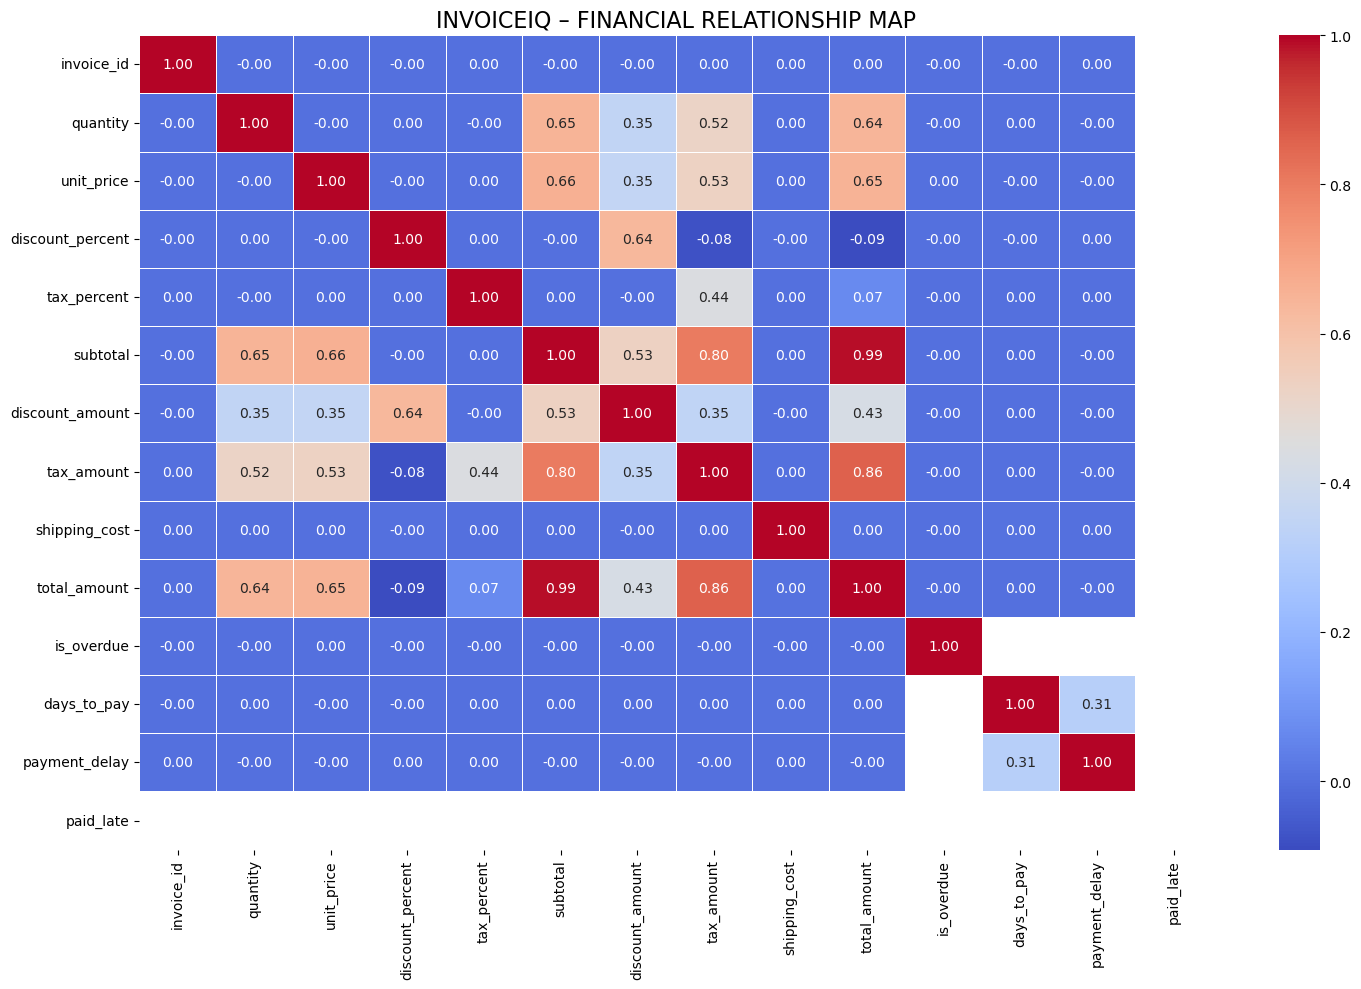

In [58]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    'INVOICEIQ – FINANCIAL RELATIONSHIP MAP',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [59]:
weekday_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

weekday_df['weekday'] = pd.to_datetime(
    weekday_df['invoice_date']
).dt.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_analysis = weekday_df.groupby('weekday').agg(
    total_invoices=('invoice_id', 'count'),
    average_delay=('payment_delay', 'mean')
).reindex(weekday_order).reset_index()

display(weekday_analysis.round(2))

,weekday,total_invoices,average_delay
0,Monday,195500,-15.09
1,Tuesday,195357,-15.06
2,Wednesday,195487,-15.00
3,Thursday,193639,-15.01
4,Friday,192691,-15.03
5,Saturday,192998,-14.99
6,Sunday,193147,-14.96


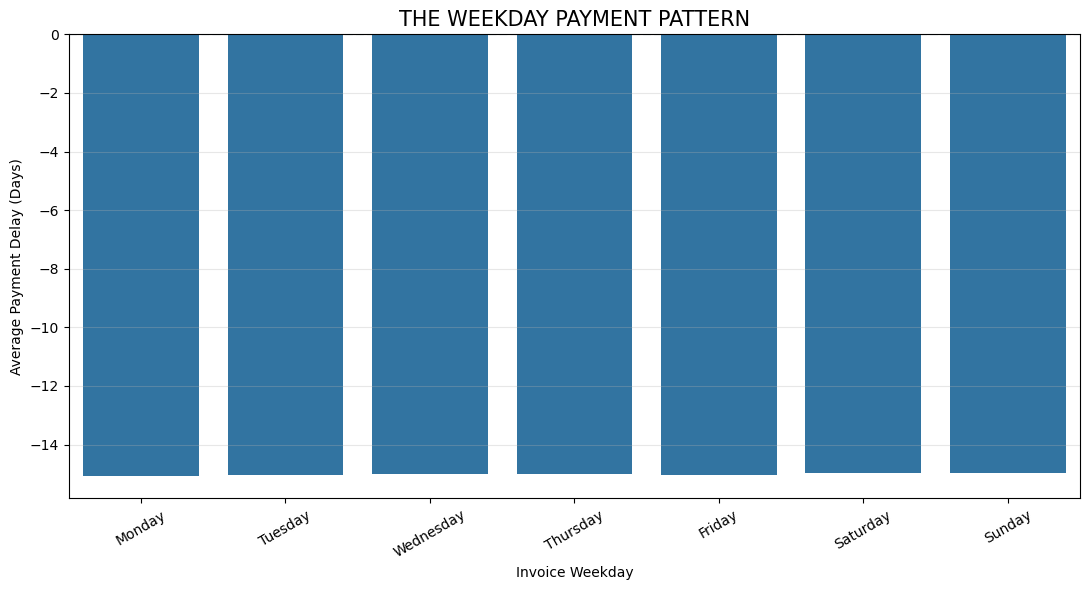

In [60]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=weekday_analysis,
    x='weekday',
    y='average_delay'
)

plt.title('THE WEEKDAY PAYMENT PATTERN', fontsize=15)
plt.xlabel('Invoice Weekday')
plt.ylabel('Average Payment Delay (Days)')
plt.xticks(rotation=30)
plt.axhline(y=0, linestyle='--')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
# Select paid invoices with valid payment outcomes
paid_analysis = df[
    (df['payment_status'] == 'Paid') &
    (df['paid_late'].notna())
].copy()

# Customer-level analysis
customer_summary = paid_analysis.groupby(
    ['customer_id', 'customer_name']
).agg(
    total_invoices=('invoice_id', 'count'),
    late_payments=('paid_late', 'sum'),
    average_delay=('payment_delay', 'mean')
).reset_index()

# Calculate late payment percentage
customer_summary['late_payment_rate'] = (
    customer_summary['late_payments'] /
    customer_summary['total_invoices']
) * 100

# Focus on repeat customers with at least 5 paid invoices
repeat_customers = customer_summary[
    customer_summary['total_invoices'] >= 5
]

# Top 15 late-paying customers
top_late_payers = repeat_customers.sort_values(
    'late_payment_rate',
    ascending=False
).head(15)

display(top_late_payers.round(2))

# Overall on-time vs late payment share
payment_share = paid_analysis['paid_late'].value_counts(
    normalize=True
).mul(100)

print("\nPayment Behaviour:")
print(payment_share.round(2))

,customer_id,customer_name,total_invoices,late_payments,average_delay,late_payment_rate
0,CUST-000000,Arjun Patel,26,0.0,-19.23,0.0
1,CUST-000001,Sarah Smith,10,0.0,-15.40,0.0
2,CUST-000002,Jennifer Wang,22,0.0,-23.27,0.0
3,CUST-000003,John Williams,26,0.0,-15.62,0.0
4,CUST-000004,John Singh,22,0.0,-15.50,0.0
5,CUST-000005,Hiro Watanabe,22,0.0,-13.05,0.0
6,CUST-000006,Arjun Singh,20,0.0,-16.35,0.0
7,CUST-000007,Elizabeth Patel,16,0.0,-10.88,0.0
8,CUST-000008,Ananya Johnson,24,0.0,-16.33,0.0
9,CUST-000009,Arjun Gupta,15,0.0,-14.40,0.0



Payment Behaviour:
paid_late
0.0    100.0
Name: proportion, dtype: float64


In [62]:
# Total invoices
total_invoices = df['invoice_id'].nunique()

# Check currency distribution before summing amounts
print("Currency distribution:")
display(df['currency'].value_counts())

# Outstanding invoices
outstanding_df = df[
    df['payment_status'].isin(['Pending', 'Overdue'])
].copy()

# Past-due invoices
overdue_df = df[
    df['payment_status'] == 'Overdue'
].copy()

# Average delay among paid invoices
paid_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
]

print("\nINVOICEIQ – BUSINESS OVERVIEW")
print("--------------------------------")
print("Total Invoices:", total_invoices)
print("Outstanding Invoice Count:", len(outstanding_df))
print("Past-Due Invoice Count:", len(overdue_df))
print("Average Payment Delay:",
      round(paid_df['payment_delay'].mean(), 2), "days")

Currency distribution:


currency
INR    600316
USD    598866
EUR    300092
GBP    200817
AUD    160024
CAD    139885
Name: count, dtype: int64


INVOICEIQ – BUSINESS OVERVIEW
--------------------------------
Total Invoices: 2000000
Outstanding Invoice Count: 540792
Past-Due Invoice Count: 199777
Average Payment Delay: -15.02 days


In [63]:
outstanding_by_currency = outstanding_df.groupby(
    'currency'
).agg(
    outstanding_invoices=('invoice_id', 'count'),
    outstanding_amount=('total_amount', 'sum')
).reset_index()

display(outstanding_by_currency.round(2))

,currency,outstanding_invoices,outstanding_amount
0,AUD,43381,1.476761e+09
1,CAD,37835,1.277527e+09
2,EUR,81196,2.765969e+09
3,GBP,54055,1.849015e+09
4,INR,162031,5.510845e+09
5,USD,162294,5.499938e+09


In [64]:
aging_df = df[
    df['payment_status'].isin(['Pending', 'Overdue'])
].copy()

aging_df['due_date'] = pd.to_datetime(
    aging_df['due_date']
)

today = pd.Timestamp.today().normalize()

aging_df['days_past_due'] = (
    today - aging_df['due_date']
).dt.days

aging_df['aging_bucket'] = pd.cut(
    aging_df['days_past_due'],
    bins=[-float('inf'), -1, 30, 60, 90, float('inf')],
    labels=[
        'Not Yet Due',
        '0-30 Days',
        '31-60 Days',
        '61-90 Days',
        '90+ Days'
    ]
)

display(aging_df['aging_bucket'].value_counts().sort_index())

aging_bucket
Not Yet Due         0
0-30 Days           0
31-60 Days          0
61-90 Days          0
90+ Days       540792
Name: count, dtype: int64

In [65]:
aging_summary = aging_df.groupby(
    ['currency', 'aging_bucket'],
    observed=False
).agg(
    invoice_count=('invoice_id', 'count'),
    outstanding_amount=('total_amount', 'sum')
).reset_index()

display(aging_summary.round(2))

,currency,aging_bucket,invoice_count,outstanding_amount
0,AUD,Not Yet Due,0,0.000000e+00
1,AUD,0-30 Days,0,0.000000e+00
2,AUD,31-60 Days,0,0.000000e+00
3,AUD,61-90 Days,0,0.000000e+00
4,AUD,90+ Days,43381,1.476761e+09
5,CAD,Not Yet Due,0,0.000000e+00
6,CAD,0-30 Days,0,0.000000e+00
7,CAD,31-60 Days,0,0.000000e+00
8,CAD,61-90 Days,0,0.000000e+00
9,CAD,90+ Days,37835,1.277527e+09


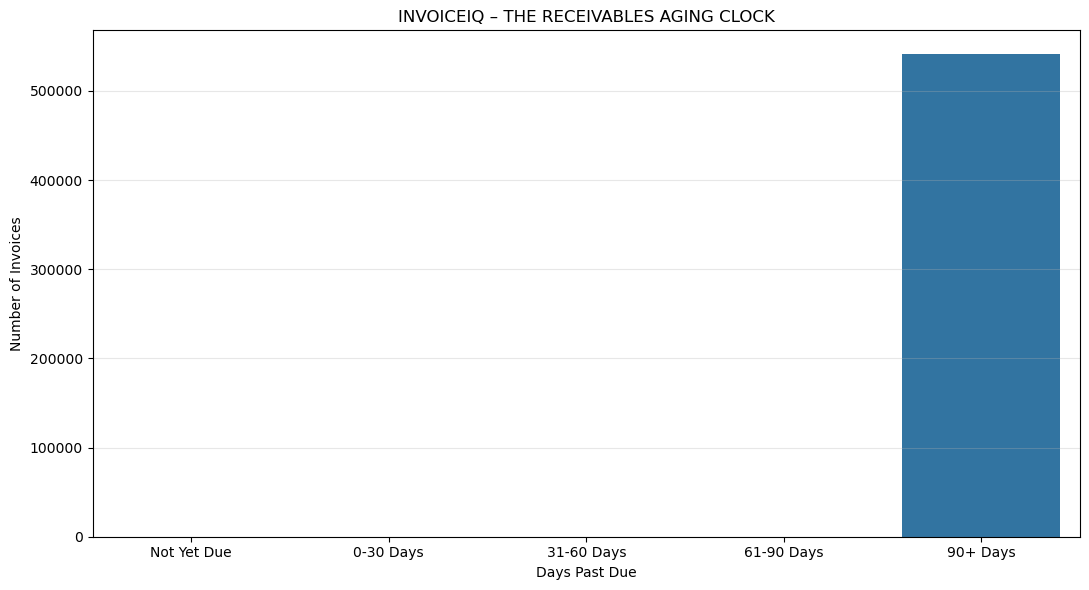

In [66]:
aging_counts = (
    aging_df['aging_bucket']
    .value_counts()
    .reindex([
        'Not Yet Due',
        '0-30 Days',
        '31-60 Days',
        '61-90 Days',
        '90+ Days'
    ])
    .reset_index()
)

aging_counts.columns = ['aging_bucket', 'invoice_count']

plt.figure(figsize=(11, 6))

sns.barplot(
    data=aging_counts,
    x='aging_bucket',
    y='invoice_count'
)

plt.title('INVOICEIQ – THE RECEIVABLES AGING CLOCK')
plt.xlabel('Days Past Due')
plt.ylabel('Number of Invoices')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nAvailable chart-related analysis objects:")
print([
    'monthly_invoices',
    'monthly_delay_trend',
    'seasonal_analysis',
    'month_end_analysis',
    'quarter_analysis',
    'correlation_matrix',
    'weekday_analysis',
    'customer_summary',
    'aging_summary'
])

Total rows: 2000000
Total columns: 37

Available chart-related analysis objects:
['monthly_invoices', 'monthly_delay_trend', 'seasonal_analysis', 'month_end_analysis', 'quarter_analysis', 'correlation_matrix', 'weekday_analysis', 'customer_summary', 'aging_summary']


In [69]:
# INVOICEIQ – EDA INSIGHT SUMMARY

paid_df = df[
    (df['payment_status'] == 'Paid') &
    (df['payment_delay'].notna())
].copy()

print("1. TOTAL INVOICES:", df['invoice_id'].nunique())

print("\n2. PAYMENT STATUS DISTRIBUTION:")
display(df['payment_status'].value_counts())

print("\n3. AVERAGE PAYMENT DELAY:")
print(round(paid_df['payment_delay'].mean(), 2), "days")

print("\n4. LATE PAYMENT RATE:")
print(round(paid_df['paid_late'].mean() * 100, 2), "%")

print("\n5. AVERAGE INVOICE VALUE:")
display(df.groupby('currency')['total_amount'].mean().round(2))

print("\n6. PAYMENT METHOD PERFORMANCE:")
display(
    paid_df.groupby('payment_method')['payment_delay']
    .mean().sort_values(ascending=False).round(2)
)

print("\n7. CUSTOMER PAYMENT PERFORMANCE:")
display(
    paid_df.groupby('customer_name')
    .agg(
        invoices=('invoice_id', 'count'),
        average_delay=('payment_delay', 'mean'),
        late_payments=('paid_late', 'sum')
    )
    .sort_values('average_delay', ascending=False)
    .head(10).round(2)
)

print("\n8. MONTHLY INVOICE VOLUME:")
display(
    df.groupby(df['invoice_date'].dt.to_period('M'))
    ['invoice_id'].count().tail(12)
)

1. TOTAL INVOICES: 2000000

2. PAYMENT STATUS DISTRIBUTION:


payment_status
Paid         1358819
Pending       341015
Overdue       199777
Cancelled     100389
Name: count, dtype: int64


3. AVERAGE PAYMENT DELAY:
-15.02 days

4. LATE PAYMENT RATE:
0.0 %

5. AVERAGE INVOICE VALUE:


currency
AUD    34001.11
CAD    33932.52
EUR    33925.16
GBP    34102.87
INR    33973.63
USD    33975.32
Name: total_amount, dtype: float64


6. PAYMENT METHOD PERFORMANCE:


payment_method
Debit Card       -14.98
Bank Transfer    -15.00
Digital Wallet   -15.00
Credit Card      -15.02
UPI              -15.03
Cheque           -15.05
Cash             -15.13
Name: payment_delay, dtype: float64


7. CUSTOMER PAYMENT PERFORMANCE:


,invoices,average_delay,late_payments
customer_name,,,
Rohan Liu,809,-13.62,0.0
Priya Smith,521,-13.68,0.0
Sai Sharma,813,-13.79,0.0
Joseph Park,707,-13.85,0.0
Karen Chen,812,-13.88,0.0
John Wang,988,-13.93,0.0
Yuki Tanaka,923,-13.94,0.0
Jessica Martinez,833,-13.95,0.0
Aarav Li,938,-13.95,0.0



8. MONTHLY INVOICE VOLUME:


invoice_date
2025-01    84867
2025-02    76615
2025-03    84981
2025-04    81652
2025-05    85047
2025-06    82185
2025-07    84866
2025-08    84965
2025-09    82131
2025-10    85113
2025-11    81757
2025-12    84705
Freq: M, Name: invoice_id, dtype: int64

In [70]:
# INVOICEIQ – PAYMENT DELAY VALIDATION

print("PAYMENT DELAY DISTRIBUTION:")
display(paid_df['payment_delay'].describe().round(2))

print("\nPAID LATE VALUE COUNTS:")
display(paid_df['paid_late'].value_counts(dropna=False))

print("\nPAYMENTS MADE EARLY:")
print((paid_df['payment_delay'] < 0).sum())

print("\nPAYMENTS MADE ON DUE DATE:")
print((paid_df['payment_delay'] == 0).sum())

print("\nPAYMENTS MADE LATE:")
print((paid_df['payment_delay'] > 0).sum())

print("\nLATEST PAYMENT DELAY:")
print(paid_df['payment_delay'].max())

PAYMENT DELAY DISTRIBUTION:


count    1358819.00
mean         -15.02
std           12.16
min          -60.00
25%          -22.00
50%          -12.00
75%           -6.00
max            0.00
Name: payment_delay, dtype: float64


PAID LATE VALUE COUNTS:


paid_late
0.0    1358819
Name: count, dtype: int64


PAYMENTS MADE EARLY:
1305067

PAYMENTS MADE ON DUE DATE:
53752

PAYMENTS MADE LATE:
0

LATEST PAYMENT DELAY:
0.0


insights = [
    {
        "Insight": "The dataset contains 2 million invoices.",
        "Business Impact": "Provides a large transaction base for analysis.",
        "ML Hypothesis": "Historical invoice data can support payment prediction."
    },
    {
        "Insight": "Paid invoices form the largest payment category.",
        "Business Impact": "Most recorded invoices have been settled.",
        "ML Hypothesis": "Payment status patterns may help identify settlement behaviour."
    },
    {
        "Insight": "341,015 invoices are Pending.",
        "Business Impact": "These invoices require payment monitoring.",
        "ML Hypothesis": "Invoice age and customer history may help predict settlement."
    },
    {
        "Insight": "199,777 invoices are marked Overdue.",
        "Business Impact": "These invoices may require collection follow-up.",
        "ML Hypothesis": "Customer history and invoice characteristics may predict overdue risk."
    },
    {
        "Insight": "Average payment delay is -15.02 days.",
        "Business Impact": "Paid invoices were settled early on average.",
        "ML Hypothesis": "Invoice terms and customer behaviour may explain payment timing."
    },
    {
        "Insight": "Payment methods have similar average delays.",
        "Business Impact": "No major difference is visible in the current averages.",
        "ML Hypothesis": "Payment method may have limited predictive value."
    },
    {
        "Insight": "The displayed top customers have negative average delays.",
        "Business Impact": "These customers appear to pay before due dates on average.",
        "ML Hypothesis": "Customer payment history may help predict future payment behaviour."
    },
    {
        "Insight": "Monthly invoice volume remains relatively consistent.",
        "Business Impact": "Transaction activity appears stable across 2025.",
        "ML Hypothesis": "Month and seasonality may help forecast invoice volume."
    },
    {
        "Insight": "The dataset contains six different currencies.",
        "Business Impact": "Financial reporting should separate currencies.",
        "ML Hypothesis": "Currency may be useful as a categorical model feature."
    },
    {
        "Insight": "Payment delay is negative on average.",
        "Business Impact": "Early settlement is an important pattern to investigate.",
        "ML Hypothesis": "Invoice amount, customer history and due dates may help predict payment timing."
    }
]

insights_df = pd.DataFrame(insights)

display(insights_df)

insights_df.to_csv(
    r"C:\Users\sridevi\Documents\InvoiceIQ\reports\eda_insights.csv",
    index=False
)

print("EDA insights saved successfully!")
